# Customer Churn Prediction 

**Business problem:** A telecom company is losing customers. Can we predict who will leave, so the company can offer them a deal *before* they go?

**Steps:** Load data > Explore > Clean > Train models > Check results > Give a business recommendation.



## Step 1: Load the data

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

# If the link does not work: download "Telco Customer Churn" from Kaggle,
# upload the CSV to Colab, and use:  df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Step 2: Explore the data
First question: how many customers leave? (This is the **churn rate**.)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn rate: 26.5%


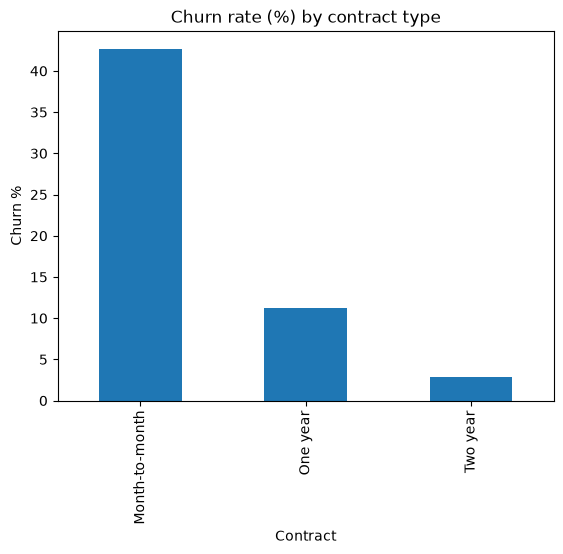

In [22]:
print(df["Churn"].value_counts())
print("Churn rate: %.1f%%" % ((df["Churn"] == "Yes").mean() * 100))

# Churn rate by contract type
(df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean() * 100)
   .plot(kind="bar", title="Churn rate (%) by contract type"))
plt.ylabel("Churn %")
plt.show()

Customers with month-to-month contracts leave much more than customers with long contracts.

## Step 3: Clean the data

In [23]:
# TotalCharges has some blank spaces, so it is read as text. Convert to number.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())

# These are new customers (tenure = 0), so total charge is 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# customerID is only a label, not useful for prediction
df = df.drop(columns=["customerID"])

# Target: Yes -> 1, No -> 0
df["Churn"] = (df["Churn"] == "Yes").astype(int)
df.info()

Missing TotalCharges: 11
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-n

## Step 4: Prepare features
Models need numbers, so we convert text columns using **one-hot encoding**.

In [24]:
X = pd.get_dummies(df.drop(columns=["Churn"]), drop_first=True)
y = df["Churn"]
print("Number of features:", X.shape[1])

Number of features: 30


## Step 5: Split into train and test
`stratify=y` keeps the same churn ratio in both parts.

In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify = y)
print(X_train.shape, X_test.shape)

(5634, 30) (1409, 30)


## Step 6: Train two models
Only about 1 in 4 customers churn, so the data is **imbalanced**. We use `class_weight="balanced"` so the model pays more attention to churners.

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

log_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight="balanced"))
log_model.fit(X_train, y_train)

rf_model = RandomForestClassifier(
    n_estimators=200, max_depth=8, class_weight="balanced", random_state=42)
rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 T

## Step 7: Check the results
Do not look at accuracy only. **Recall** for churners (class 1) tells us how many leaving customers we caught.

===== Logistic Regression =====
              precision    recall  f1-score   support

      Stayed       0.92      0.72      0.81      1036
     Churned       0.52      0.82      0.63       373

    accuracy                           0.75      1409
   macro avg       0.72      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409

ROC-AUC: 0.862

===== Random Forest =====
              precision    recall  f1-score   support

      Stayed       0.93      0.73      0.82      1036
     Churned       0.53      0.84      0.65       373

    accuracy                           0.76      1409
   macro avg       0.73      0.79      0.74      1409
weighted avg       0.82      0.76      0.78      1409

ROC-AUC: 0.865



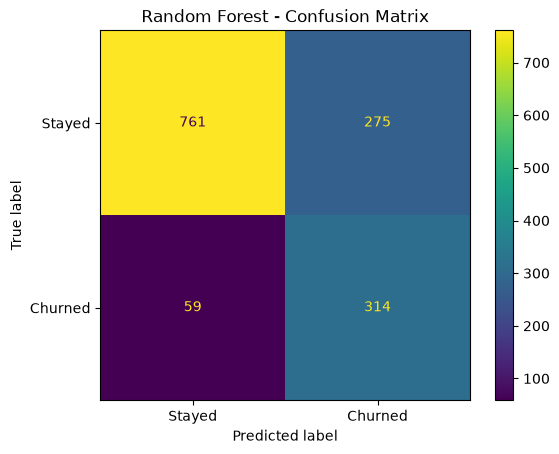

In [34]:
from sklearn.metrics import classification_report, roc_auc_score, ConfusionMatrixDisplay

for name, model in [("Logistic Regression", log_model), ("Random Forest", rf_model)]:
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    print("=====", name, "=====")
    print(classification_report(y_test, pred, target_names=["Stayed", "Churned"]))
    print("ROC-AUC: %.3f\n" % roc_auc_score(y_test, prob))

ConfusionMatrixDisplay.from_estimator(rf_model, X_test, y_test, display_labels=["Stayed", "Churned"])
plt.title("Random Forest - Confusion Matrix")
plt.show()

**How to read it:**
- *Precision (churned):* of the customers we said will leave, how many really left?
- *Recall (churned):* of all customers who really left, how many did we catch?
- Here, **missing a churner costs more than a wrong alarm**, so recall matters a lot.

## Step 8: Which factors cause churn?

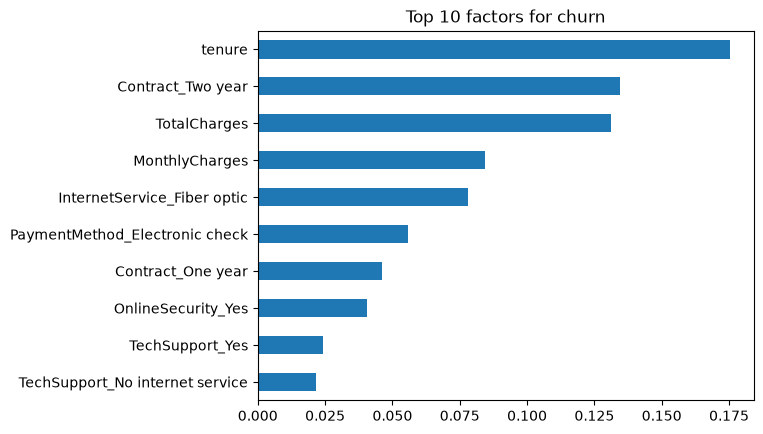

In [35]:
importance = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
importance.head(10).sort_values().plot(kind="barh", title="Top 10 factors for churn")
plt.show()

## Step 9: Tune the decision threshold
By default a customer is called "churn" if probability is above 0.5. If we lower it, we catch more churners (higher recall) but make more false alarms.

In [36]:
from sklearn.metrics import precision_score, recall_score

prob = rf_model.predict_proba(X_test)[:, 1]
for t in [0.3, 0.4, 0.5, 0.6]:
    pred_t = (prob >= t).astype(int)
    print("Threshold %.1f -> Precision %.2f | Recall %.2f" % (
        t, precision_score(y_test, pred_t), recall_score(y_test, pred_t)))

Threshold 0.3 -> Precision 0.42 | Recall 0.94
Threshold 0.4 -> Precision 0.47 | Recall 0.90
Threshold 0.5 -> Precision 0.53 | Recall 0.84
Threshold 0.6 -> Precision 0.61 | Recall 0.72


## Step 10: Business recommendation
Now we turn the model into a **decision**. We find customers who are *high risk* and *high value* (they pay more), and target them first.

             customers  monthly_revenue
Risk group                             
High risk          444          33183.0
Low risk           582          29688.0
Medium risk        383          27800.0

Customers to target first (high risk + high value): 312
Monthly revenue at risk: 27192


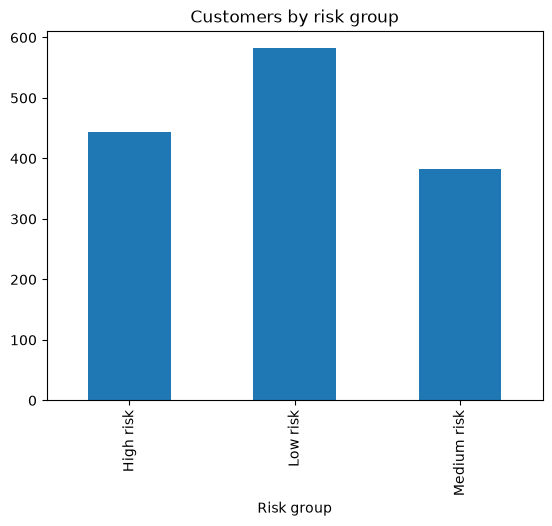

In [37]:
risk = X_test.copy()
risk["churn_prob"] = prob
risk["MonthlyCharges"] = df.loc[X_test.index, "MonthlyCharges"]

high_value_cutoff = df["MonthlyCharges"].median()
risk["Risk group"] = np.where(
    risk["churn_prob"] >= 0.6, "High risk",
    np.where(risk["churn_prob"] >= 0.3, "Medium risk", "Low risk"))

summary = risk.groupby("Risk group").agg(
    customers=("churn_prob", "size"),
    monthly_revenue=("MonthlyCharges", "sum")).round(0)
print(summary)

target = risk[(risk["Risk group"] == "High risk") & (risk["MonthlyCharges"] >= high_value_cutoff)]
print("\nCustomers to target first (high risk + high value):", len(target))
print("Monthly revenue at risk: %.0f" % target["MonthlyCharges"].sum())

summary["customers"].plot(kind="bar", title="Customers by risk group")
plt.show()